# Assignment 1: Data Profiling (EDA)

**Course:** TTTC3213 Data Engineering

**Project:** Intelligent Logistics Analysis

**Dataset:** Brazilian E-Commerce Public Dataset by Olist

**Group Members:**
- Ma Zhongxiao – A214013
- Wang Rui – A214077
- Xia Mingcong – A207390
## 1. Scenario

This project focuses on delivery data from an e-commerce platform in Brazil. The dataset may contain missing values, outliers, duplicate records, and other data quality problems. We want to check these problems and clean the data to make it more reliable for logistics analysis.

## 2. Data Source

**Dataset:** Brazilian E-Commerce Public Dataset by Olist

**Source:** Kaggle

**URL:** https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

**How we obtained the data:**

We downloaded the dataset from Kaggle as a ZIP file and extracted the CSV files. The dataset contains real e-commerce orders from Brazil between 2016 and 2018. We use Python and Pandas to load and check the data.

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset location
data_path = Path("data")

# Download dataset only if files are missing
if not (data_path / "olist_orders_dataset.csv").exists():
    import subprocess
    import sys

    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "kagglehub"
    ])

    import kagglehub

    print("Downloading Olist dataset from Kaggle...")
    downloaded_path = Path(
        kagglehub.dataset_download("olistbr/brazilian-ecommerce")
    )
    data_path = downloaded_path

# Load datasets
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")
items = pd.read_csv(data_path / "olist_order_items_dataset.csv")
customers = pd.read_csv(data_path / "olist_customers_dataset.csv")
geo = pd.read_csv(data_path / "olist_geolocation_dataset.csv")

# Display dataset sizes
print("Orders:", orders.shape)
print("Order Items:", items.shape)
print("Customers:", customers.shape)
print("Geolocation:", geo.shape)


Orders: (99441, 8)
Order Items: (112650, 7)
Customers: (99441, 5)
Geolocation: (1000163, 5)


## 3. Data Profiling and Issue Handling

We first check the structure of the datasets, including column names, data types, missing values, and duplicate records. This helps us understand the data quality problems before cleaning.

In [2]:
# Check dataset information
datasets = {
    "Orders": orders,
    "Order Items": items,
    "Customers": customers,
    "Geolocation": geo
}

for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print("Rows and Columns:", df.shape)
    print("\nColumn Information:")
    df.info()
    print("\nFirst 5 Rows:")
    display(df.head())


===== Orders =====
Rows and Columns: (99441, 8)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

First 5 Rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



===== Order Items =====
Rows and Columns: (112650, 7)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB

First 5 Rows:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



===== Customers =====
Rows and Columns: (99441, 5)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

First 5 Rows:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



===== Geolocation =====
Rows and Columns: (1000163, 5)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB

First 5 Rows:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [3]:
# Check missing values and duplicate rows
for name, df in datasets.items():
    print(f"\n===== {name} =====")

    missing = df.isnull().sum()
    missing_percent = (missing / len(df) * 100).round(2)

    missing_table = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage (%)": missing_percent
    })

    display(missing_table)

    print("Duplicate Rows:", df.duplicated().sum())


===== Orders =====


,Missing Count,Missing Percentage (%)
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00


Duplicate Rows: 0

===== Order Items =====


,Missing Count,Missing Percentage (%)
order_id,0,0.0
order_item_id,0,0.0
product_id,0,0.0
seller_id,0,0.0
shipping_limit_date,0,0.0
price,0,0.0
freight_value,0,0.0


Duplicate Rows: 0

===== Customers =====


,Missing Count,Missing Percentage (%)
customer_id,0,0.0
customer_unique_id,0,0.0
customer_zip_code_prefix,0,0.0
customer_city,0,0.0
customer_state,0,0.0


Duplicate Rows: 0

===== Geolocation =====


,Missing Count,Missing Percentage (%)
geolocation_zip_code_prefix,0,0.0
geolocation_lat,0,0.0
geolocation_lng,0,0.0
geolocation_city,0,0.0
geolocation_state,0,0.0


Duplicate Rows: 261831


### 3.1 Missing Value Analysis

We found missing values in three date columns in the Orders dataset. Before cleaning the data, we need to check the order status because some orders may be canceled or not delivered yet.

In [4]:

# Check order status
print("Order Status Distribution:")
display(orders["order_status"].value_counts())

# Check missing delivery dates by order status
print("\nMissing Delivery Dates by Order Status:")

missing_delivery = orders[
    orders["order_delivered_customer_date"].isnull()
]

display(
    missing_delivery["order_status"].value_counts()
)

# Check missing approval dates by order status
print("\nMissing Approval Dates by Order Status:")

missing_approval = orders[
    orders["order_approved_at"].isnull()
]

display(
    missing_approval["order_status"].value_counts()
)


Order Status Distribution:


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


Missing Delivery Dates by Order Status:


order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


Missing Approval Dates by Order Status:


order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

### 3.2 Handling Missing Values

Most missing delivery dates belong to orders that were not delivered. These missing values may be normal, so we keep them.

However, we found 8 delivered orders without a delivery date and 14 delivered orders without an approval date. We flag these records as data quality issues instead of removing them. We do not fill in fake dates because this may affect the delivery time analysis.

In [5]:

# Create a copy for cleaning
orders_clean = orders.copy()

# Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors="coerce"
    )

# Flag missing dates in delivered orders
orders_clean["missing_delivery_flag"] = (
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].isna())
)

orders_clean["missing_approval_flag"] = (
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_approved_at"].isna())
)

# Show results
print("Delivered orders missing delivery date:",
      orders_clean["missing_delivery_flag"].sum())

print("Delivered orders missing approval date:",
      orders_clean["missing_approval_flag"].sum())

print("\nDate column types:")
print(orders_clean[date_columns].dtypes)

print("\nFlagged records:")
display(
    orders_clean[
        orders_clean["missing_delivery_flag"] |
        orders_clean["missing_approval_flag"]
    ][
        ["order_id", "order_status",
         "order_approved_at",
         "order_delivered_customer_date",
         "missing_delivery_flag",
         "missing_approval_flag"]
    ].head(10)
)


Delivered orders missing delivery date: 8
Delivered orders missing approval date: 14

Date column types:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Flagged records:


,order_id,order_status,order_approved_at,order_delivered_customer_date,missing_delivery_flag,missing_approval_flag
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:56:40,NaT,True,False
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,NaT,2017-03-01 13:25:33,False,True
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,NaT,2017-03-02 10:05:06,False,True
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,NaT,2017-03-01 08:07:38,False,True
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 07:19:05,NaT,True,False
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,NaT,2017-03-09 07:28:47,False,True
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,NaT,2017-03-02 11:09:19,False,True
26800,c1d4211b3dae76144deccd6c74144a88,delivered,NaT,2017-01-30 18:16:01,False,True
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,NaT,2017-03-02 03:41:58,False,True
39334,d77031d6a3c8a52f019764e68f211c69,delivered,NaT,2017-03-02 16:15:23,False,True


### 3.3 Duplicate Records

We found 261,831 duplicate rows in the Geolocation dataset. These rows have exactly the same values in all columns.

We remove only the fully duplicated rows to reduce repeated data. We keep records with the same ZIP code but different coordinates because they may represent different locations.

In [6]:

# Make a copy of the original geolocation data
geo_clean = geo.copy()

# Count duplicate rows before cleaning
duplicates_before = geo_clean.duplicated().sum()
rows_before = len(geo_clean)

# Remove fully duplicated rows
geo_clean = geo_clean.drop_duplicates().reset_index(drop=True)

# Check results after cleaning
rows_after = len(geo_clean)
duplicates_after = geo_clean.duplicated().sum()

print("Rows before cleaning:", rows_before)
print("Duplicate rows found:", duplicates_before)
print("Rows after cleaning:", rows_after)
print("Duplicates remaining:", duplicates_after)
print("Rows removed:", rows_before - rows_after)

# Show the first 5 cleaned records
display(geo_clean.head())


Rows before cleaning: 1000163
Duplicate rows found: 261831
Rows after cleaning: 738332
Duplicates remaining: 0
Rows removed: 261831


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


### 3.4 Outlier Detection – Delivery Time

We calculate the delivery time using the order purchase date and the actual delivery date. We use the IQR method and a boxplot to find unusual delivery times.

We also check for negative delivery times because they may indicate incorrect date records.

In [7]:

# Use delivered orders with valid dates
delivery_data = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].notna())
].copy()

# Calculate delivery time in days
delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"] -
    delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Check invalid delivery times
negative_count = (delivery_data["delivery_days"] < 0).sum()
print("Negative delivery times:", negative_count)

# Use non-negative delivery times for IQR
valid_delivery = delivery_data[
    delivery_data["delivery_days"] >= 0
].copy()

# Calculate IQR
Q1 = valid_delivery["delivery_days"].quantile(0.25)
Q3 = valid_delivery["delivery_days"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = valid_delivery[
    (valid_delivery["delivery_days"] < lower_bound) |
    (valid_delivery["delivery_days"] > upper_bound)
]

print("\nDelivery Time Statistics:")
print("Minimum:", round(valid_delivery["delivery_days"].min(), 2))
print("Maximum:", round(valid_delivery["delivery_days"].max(), 2))
print("Mean:", round(valid_delivery["delivery_days"].mean(), 2))
print("Median:", round(valid_delivery["delivery_days"].median(), 2))

print("\nIQR Results:")
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Outliers Found:", len(outliers))

# Show the 5 largest delivery times
print("\nTop 5 Longest Delivery Times:")
display(
    valid_delivery.nlargest(5, "delivery_days")[
        ["order_id", "order_status", "delivery_days"]
    ]
)


Negative delivery times: 0

Delivery Time Statistics:
Minimum: 0.53
Maximum: 209.63
Mean: 12.56
Median: 10.22

IQR Results:
Q1: 6.77
Q3: 15.72
IQR: 8.95
Lower Bound: -6.66
Upper Bound: 29.15
Outliers Found: 4896

Top 5 Longest Delivery Times:


,order_id,order_status,delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,delivered,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,208.351759
61610,440d0d17af552815d15a9e41abe49359,delivered,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,194.850174
89130,285ab9426d6982034523a855f55a885e,delivered,194.633611


/tmp/ipykernel_14900/156956711.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valid_delivery["delivery_days"], vert=False)


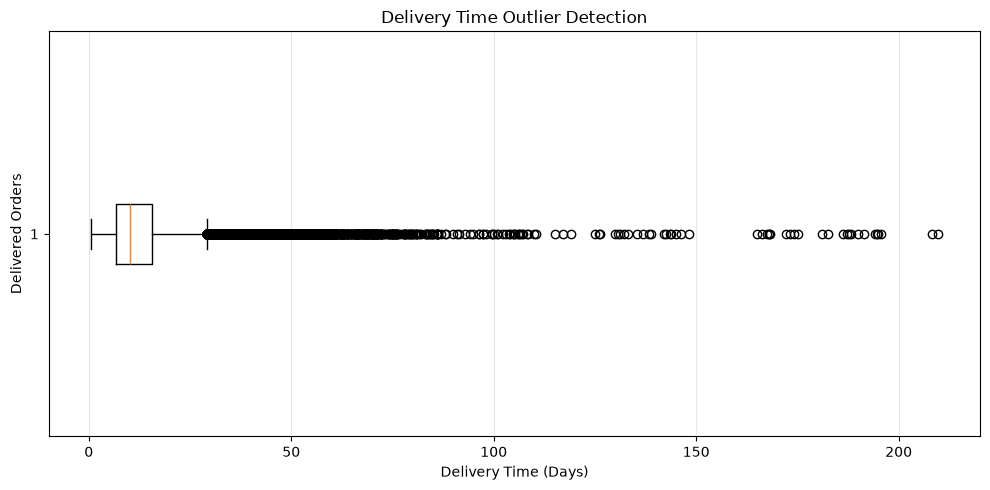

Minimum: 0.53
Maximum: 209.63
Median: 10.22
Upper IQR Bound: 29.15
Number of Outliers: 4896


In [8]:

# Boxplot of delivery time
plt.figure(figsize=(10, 5))

plt.boxplot(valid_delivery["delivery_days"], vert=False)

plt.title("Delivery Time Outlier Detection")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Delivered Orders")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Print special values after the chart
print("Minimum:", round(valid_delivery["delivery_days"].min(), 2))
print("Maximum:", round(valid_delivery["delivery_days"].max(), 2))
print("Median:", round(valid_delivery["delivery_days"].median(), 2))
print("Upper IQR Bound:", round(upper_bound, 2))
print("Number of Outliers:", len(outliers))


### 3.5 Handling Delivery Time Outliers

We found 4,896 delivery time outliers using the IQR method. The longest delivery time was 209.63 days, while the median was 10.22 days.

We decided to keep these records and add an outlier flag. Long delivery times may be real delivery delays, so removing them could cause us to lose useful information. These records can be checked again in future analysis.

In [9]:

# Create an outlier flag
valid_delivery["delivery_outlier_flag"] = (
    (valid_delivery["delivery_days"] < lower_bound) |
    (valid_delivery["delivery_days"] > upper_bound)
)

# Count flagged records
print("Total valid delivery records:", len(valid_delivery))
print("Outliers flagged:", valid_delivery["delivery_outlier_flag"].sum())
print("Normal records:", (~valid_delivery["delivery_outlier_flag"]).sum())

# Show sample outliers
print("\nSample outlier records:")
display(
    valid_delivery[
        valid_delivery["delivery_outlier_flag"]
    ][
        ["order_id", "delivery_days", "delivery_outlier_flag"]
    ].head(10)
)


Total valid delivery records: 96470
Outliers flagged: 4896
Normal records: 91574

Sample outlier records:


,order_id,delivery_days,delivery_outlier_flag
29,ecab90c9933c58908d3d6add7c6f5ae3,30.401898,True
35,8563039e855156e48fccee4d611a3196,30.374757,True
41,6ea2f835b4556291ffdc53fa0b3b95e8,33.896933,True
97,6a0a8bfbbe700284feb0845d95e0867f,36.340718,True
110,9d531c565e28c3e0d756192f84d8731f,56.026481,True
115,8fc207e94fa91a7649c5a5dab690272a,54.828194,True
252,f31535f21d145b2345e2bf7f09d62322,81.334722,True
297,06ae7271902bbb087fc093137fee6e81,31.930417,True
311,4906eeadde5f70b308c20c4a8f20be02,32.555231,True
326,bca3dc20a3ec02261c5b17dc270e9e65,30.265556,True


## 4. Diagnostic Charts

### 4.1 Missing Values in Orders Dataset

This chart shows the missing values in each column of the Orders dataset. The actual delivery date has the most missing values. However, some missing dates are expected because not all orders have been delivered.

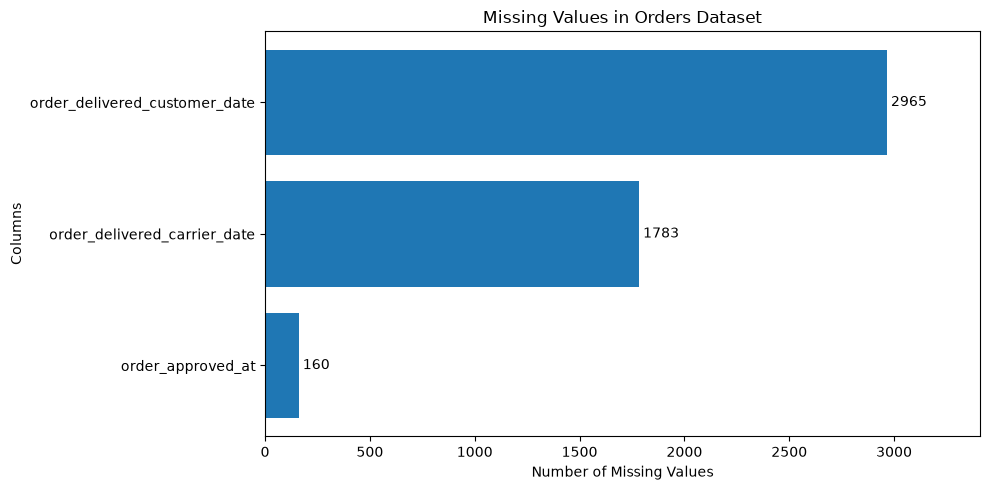

Column with most missing values: order_delivered_customer_date
Maximum missing count: 2965
Total missing cells: 4908


In [10]:

# Count missing values in orders
missing_counts = orders.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values()

# Plot missing values
plt.figure(figsize=(10, 5))

bars = plt.barh(
    missing_counts.index,
    missing_counts.values
)

plt.title("Missing Values in Orders Dataset")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")

# Add counts beside bars
for bar in bars:
    plt.text(
        bar.get_width() + 20,
        bar.get_y() + bar.get_height() / 2,
        int(bar.get_width()),
        va="center"
    )

plt.xlim(0, missing_counts.max() * 1.15)
plt.tight_layout()
plt.show()

# Print special values after the chart
print("Column with most missing values:", missing_counts.idxmax())
print("Maximum missing count:", missing_counts.max())
print("Total missing cells:", missing_counts.sum())


### 3.6 Other Data Quality Issues

We also check for invalid values and inconsistent data. For example, an order should not be delivered before it was purchased. We check the date order and geographical coordinates to find possible data quality problems.

In [11]:

# Check invalid date order
invalid_approval = (
    orders_clean["order_approved_at"] <
    orders_clean["order_purchase_timestamp"]
).sum()

invalid_carrier = (
    orders_clean["order_delivered_carrier_date"] <
    orders_clean["order_approved_at"]
).sum()

invalid_delivery = (
    orders_clean["order_delivered_customer_date"] <
    orders_clean["order_purchase_timestamp"]
).sum()

print("Approval before purchase:", invalid_approval)
print("Carrier date before approval:", invalid_carrier)
print("Delivery before purchase:", invalid_delivery)

# Check geographical coordinate limits
invalid_lat = (
    (geo_clean["geolocation_lat"] < -90) |
    (geo_clean["geolocation_lat"] > 90)
).sum()

invalid_lng = (
    (geo_clean["geolocation_lng"] < -180) |
    (geo_clean["geolocation_lng"] > 180)
).sum()

print("\nInvalid latitude values:", invalid_lat)
print("Invalid longitude values:", invalid_lng)

# Check inconsistent text formats
print("\nCustomer state values:")
print(sorted(customers["customer_state"].dropna().unique()))

print("\nOrder status values:")
print(sorted(orders_clean["order_status"].dropna().unique()))


Approval before purchase: 0
Carrier date before approval: 1359
Delivery before purchase: 0

Invalid latitude values: 0
Invalid longitude values: 0

Customer state values:
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']

Order status values:
['approved', 'canceled', 'created', 'delivered', 'invoiced', 'processing', 'shipped', 'unavailable']


### 3.7 Handling Date Inconsistencies

We found 1,359 orders where the carrier date is earlier than the approval date. This may be caused by incorrect timestamps or differences between systems.

We keep these records and add a flag for further checking. We do not change the original dates because we cannot confirm which date is incorrect.

We also checked latitude, longitude, order status, and customer state values. No invalid coordinate ranges or inconsistent category formats were found in these checks.

In [12]:

# Flag orders with inconsistent dates
orders_clean["invalid_carrier_date_flag"] = (
    orders_clean["order_delivered_carrier_date"] <
    orders_clean["order_approved_at"]
)

# Count flagged records
print("Orders with inconsistent carrier dates:",
      orders_clean["invalid_carrier_date_flag"].sum())

# Show sample records
print("\nSample inconsistent records:")
display(
    orders_clean[
        orders_clean["invalid_carrier_date_flag"]
    ][[
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "invalid_carrier_date_flag"
    ]].head(10)
)

# Summary of quality flags
print("\nData Quality Summary:")
print("Missing delivery dates in delivered orders:",
      orders_clean["missing_delivery_flag"].sum())
print("Missing approval dates in delivered orders:",
      orders_clean["missing_approval_flag"].sum())
print("Inconsistent carrier dates:",
      orders_clean["invalid_carrier_date_flag"].sum())


Orders with inconsistent carrier dates: 1359

Sample inconsistent records:


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,invalid_carrier_date_flag
15,dcb36b511fcac050b97cd5c05de84dc3,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00,True
64,688052146432ef8253587b930b01a06d,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,True
199,58d4c4747ee059eeeb865b349b41f53a,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00,True
210,412fccb2b44a99b36714bca3fef8ad7b,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00,True
415,56a4ac10a4a8f2ba7693523bb439eede,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00,True
481,32e4fa9bb468884309b58b9348de70c3,2018-07-04 16:49:21,2018-07-05 16:33:06,2018-07-05 14:50:00,True
483,4df92d82d79c3b52c7138679fa9b07fc,2018-07-24 11:32:11,2018-07-29 23:30:52,2018-07-26 14:46:00,True
585,16e38caa92e342c7780f68832f832d4d,2018-05-07 01:09:09,2018-05-07 16:52:39,2018-05-07 15:09:00,True
615,b9afddbdcfadc9a87b41a83271c3e888,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,True
817,6051e6d3da9a50b7325cbe9c81025062,2018-07-03 23:40:16,2018-07-05 16:31:26,2018-07-04 12:14:00,True



Data Quality Summary:
Missing delivery dates in delivered orders: 8
Missing approval dates in delivered orders: 14
Inconsistent carrier dates: 1359


## 5. PII and Bias Risks

### 5.1 Personally Identifiable Information (PII)

The dataset contains customer IDs, ZIP code prefixes, cities, states, and geographical coordinates. These fields may create privacy risks when combined.

We should not publish customer-level location details or use customer IDs in public reports. We can use grouped location data, such as state-level information, to reduce privacy risks.

### 5.2 Sampling Bias

We check the number of customers in each Brazilian state to see whether the data is balanced. If some states have many more customers than others, the dataset may not represent all regions equally.

In [13]:

# Count customers by state
state_counts = customers["customer_state"].value_counts()

print("Number of states:", len(state_counts))
print("\nTop 10 states:")
display(state_counts.head(10))

print("\nBottom 5 states:")
display(state_counts.tail(5))

# Calculate percentage distribution
state_percent = (
    customers["customer_state"]
    .value_counts(normalize=True) * 100
).round(2)

print("\nTop 5 state percentages:")
display(state_percent.head(5))

# Check the largest state
print("\nState with most customers:", state_counts.idxmax())
print("Maximum customers:", state_counts.max())
print("State with fewest customers:", state_counts.idxmin())
print("Minimum customers:", state_counts.min())


Number of states: 27

Top 10 states:


customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64


Bottom 5 states:


customer_state
RO    253
AM    148
AC     81
AP     68
RR     46
Name: count, dtype: int64


Top 5 state percentages:


customer_state
SP    41.98
RJ    12.92
MG    11.70
RS     5.50
PR     5.07
Name: proportion, dtype: float64


State with most customers: SP
Maximum customers: 41746
State with fewest customers: RR
Minimum customers: 46


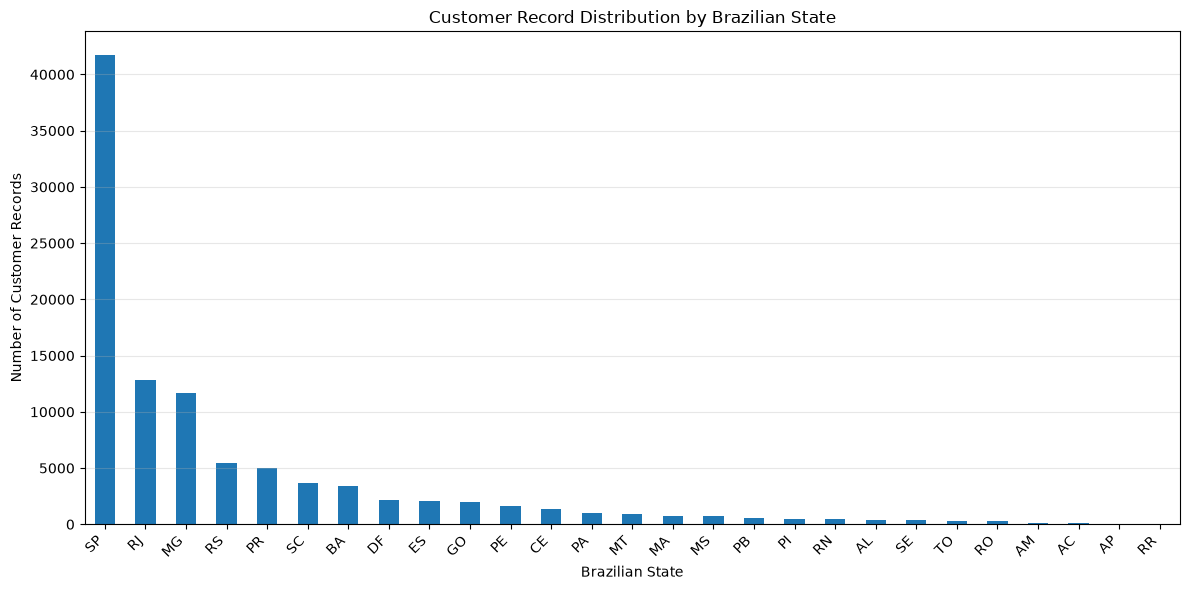

State with most records: SP
Maximum records: 41746
State with fewest records: RR
Minimum records: 46
Largest state percentage: 41.98 %


In [14]:

# Plot customer records by state
plt.figure(figsize=(12, 6))

state_counts.plot(kind="bar")

plt.title("Customer Record Distribution by Brazilian State")
plt.xlabel("Brazilian State")
plt.ylabel("Number of Customer Records")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Print special values after the chart
print("State with most records:", state_counts.idxmax())
print("Maximum records:", state_counts.max())
print("State with fewest records:", state_counts.idxmin())
print("Minimum records:", state_counts.min())
print("Largest state percentage:",
      round(state_counts.max() / state_counts.sum() * 100, 2), "%")


### 5.3 Bias Analysis and Handling

The dataset has 27 Brazilian states. São Paulo (SP) has the most customer records, with 41,746 records (41.98%). Roraima (RR) has the fewest, with only 46 records.

This shows that the data is not balanced across different regions. The results may represent states with more records better than states with fewer records.

To reduce this risk, we will compare delivery results by state instead of only using overall averages. We will also show the number of records for each state and be careful when using results from states with very little data.

We do not remove records from larger states because the differences may reflect real customer activity.

## 6. Conclusion

In this assignment, we checked the quality of the Olist e-commerce dataset.

We found 4,908 missing cells in the Orders dataset, 261,831 fully duplicated rows in the Geolocation dataset, 4,896 delivery time outliers, and 1,359 orders with inconsistent carrier dates.

We removed the fully duplicated geolocation rows, converted date columns to the correct data type, and added flags for missing dates, unusual delivery times, and inconsistent dates. We kept the original values when we could not confirm whether they were incorrect.

The dataset is suitable for logistics analysis after these cleaning steps. However, some problems still need further checking. The data also has an unbalanced regional distribution, and it only covers orders from 2016 to 2018.

Overall, the data can be used for our Intelligent Logistics Analysis project, but we need to consider these limitations when interpreting the results.

## 7. How to Run This Notebook

1. Open `Assignment1_Data_Profiling.ipynb` in Jupyter Notebook or VS Code.
2. Make sure Python, Pandas, NumPy, and Matplotlib are installed.
3. Run all cells from top to bottom.
4. If the CSV files are not available locally, the notebook will try to download the public dataset from Kaggle using `kagglehub`.
5. The notebook will display the data profiling results, cleaning steps, and diagnostic charts.

**Dataset Source:** https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

An internet connection is required for the first automatic download.